## Baseline LightGBM
- Đầu vào: `data/dataset_thr88/{train,val,test}.npz`.
- Đặc trưng: tính từ mỗi cửa sổ 60 phút (nền, xu hướng/biến động, gần đây, chất lượng), lưu ở `data/features_thr88/`.
- So sánh: LightGBM với 3 bộ đặc trưng (`nen`, `dong`, `tat_ca`) và quy tắc "SpO2 nhỏ nhất 10 phút cuối".
- Chọn bộ đặc trưng chỉ dựa trên **val**. Tập **test** chỉ chạy một lần ở Cell 5.
- Chỉ số chính: AUPRC (mốc ngẫu nhiên = tỷ lệ dương ≈ 0,012) và độ nhạy ở mức cảnh báo giả cố định. Không dùng accuracy.
- Có resume: đặc trưng và mô hình đã lưu sẽ được đọc lại. Muốn tính lại thì xóa thư mục `data/features_thr88` hoặc `models`.

trích đặc trưng

In [1]:
import os, warnings, numpy as np, pandas as pd

DATA_DIR, FEAT_DIR, MODEL_DIR = "../data/data/dataset_thr88", "../data/data/features_thr88", "models"
STRIDE = 5      # số phút giữa hai cửa sổ liên tiếp (khớp data_windowing)
CH = ["spo2_mean", "spo2_min", "spo2_valid", "pulse_mean"]
os.makedirs(FEAT_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)

def slope(Y, lo):
    """Độ dốc hồi quy tuyến tính (đơn vị/phút) trên Y[:, lo:], bỏ qua NaN."""
    y = Y[:, lo:]; t = np.arange(y.shape[1], dtype=np.float32); m = ~np.isnan(y)
    n, yy = m.sum(1), np.where(m, y, 0)
    Sx, Sy, Sxy, Sxx = (m * t).sum(1), yy.sum(1), (yy * t).sum(1), (m * t * t).sum(1)
    den = n * Sxx - Sx ** 2
    with np.errstate(all="ignore"): s = (n * Sxy - Sx * Sy) / den
    s[(n < 5) | (den == 0)] = np.nan
    return s

def frac_below(SP, thr):
    v = ~np.isnan(SP)
    return ((SP < thr) & v).sum(1) / np.maximum(v.sum(1), 1)

def make_features(X):
    SP, MN, VA, PU = (X[:, :, i] for i in range(4))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f = {
            # --- nền: mức SpO2 chung của cả cửa sổ ---
            "sp_mean": np.nanmean(SP, 1), "sp_med": np.nanmedian(SP, 1), "sp_p10": np.nanpercentile(SP, 10, axis=1),
            "mn_min60": np.nanmin(MN, 1), "frac_lt95": frac_below(SP, 95), "frac_lt92": frac_below(SP, 92),
            "frac_lt90": frac_below(SP, 90), "pu_mean": np.nanmean(PU, 1),
            # --- động: xu hướng và độ biến động ---
            "sp_slope60": slope(SP, 0), "sp_slope30": slope(SP, 30),
            "sp_d_last10_first30": np.nanmean(SP[:, 50:], 1) - np.nanmean(SP[:, :30], 1),
            "sp_std60": np.nanstd(SP, 1), "sp_std15": np.nanstd(SP[:, 45:], 1),
            "pu_slope30": slope(PU, 30), "pu_d_last10_first30": np.nanmean(PU[:, 50:], 1) - np.nanmean(PU[:, :30], 1),
            "pu_std60": np.nanstd(PU, 1),
            # --- gần đây: mức SpO2 ở những phút cuối ---
            "mn_min10": np.nanmin(MN[:, 50:], 1), "sp_last5": np.nanmean(SP[:, 55:], 1),
            # --- chất lượng tín hiệu ---
            "valid_mean": np.nanmean(VA, 1), "sp_nan_frac": np.isnan(SP).mean(1),
        }
    return pd.DataFrame(f).astype("float32")

GROUPS = {
    "nen":   ["sp_mean", "sp_med", "sp_p10", "mn_min60", "frac_lt95", "frac_lt92", "frac_lt90", "pu_mean"],
    "dong":  ["sp_slope60", "sp_slope30", "sp_d_last10_first30", "sp_std60", "sp_std15",
              "pu_slope30", "pu_d_last10_first30", "pu_std60"],
    "gan":   ["mn_min10", "sp_last5"],
    "chatluong": ["valid_mean", "sp_nan_frac"],
}

F = {}
for k in ("train", "val", "test"):
    path = f"{FEAT_DIR}/{k}.parquet"
    if os.path.exists(path):
        F[k] = pd.read_parquet(path); print(f"Đọc đặc trưng {k}: {F[k].shape}")
    else:
        z = np.load(f"{DATA_DIR}/{k}.npz")
        df = make_features(z["X"]); df["y"] = z["y"]; df["pid"] = z["pid"]; df["is_1hz"] = z["is_1hz"]
        df.to_parquet(path, index=False); F[k] = df; print(f"Đã tính và lưu đặc trưng {k}: {df.shape}")

Đọc đặc trưng train: (340195, 23)
Đọc đặc trưng val: (70513, 23)
Đọc đặc trưng test: (71600, 23)


huấn luyện và so sánh

In [2]:
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

VARIANTS = {
    "nen":    GROUPS["nen"] + GROUPS["chatluong"],
    "dong":   GROUPS["dong"] + GROUPS["chatluong"],
    "tat_ca": GROUPS["nen"] + GROUPS["dong"] + GROUPS["gan"] + GROUPS["chatluong"],
}
PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=200,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              metric="average_precision", verbose=-1, seed=42)

models, score = {}, {"val": {}, "test": {}}
for name, cols in VARIANTS.items():
    path = f"{MODEL_DIR}/lgbm_thr88_{name}.txt"
    if os.path.exists(path):
        models[name] = lgb.Booster(model_file=path); print(f"[{name}] đọc mô hình đã lưu")
    else:
        dtr = lgb.Dataset(F["train"][cols], F["train"]["y"])
        dva = lgb.Dataset(F["val"][cols], F["val"]["y"], reference=dtr)
        models[name] = lgb.train(PARAMS, dtr, 2000, valid_sets=[dva],
                                 callbacks=[lgb.early_stopping(50, verbose=False)])
        models[name].save_model(path, num_iteration=models[name].best_iteration)
        print(f"[{name}] huấn luyện xong, dừng ở vòng {models[name].best_iteration}")
    for k in ("val", "test"):
        score[k][name] = models[name].predict(F[k][cols], num_iteration=models[name].best_iteration or None)

for k in ("val", "test"):   # quy tắc đơn giản: SpO2 nhỏ nhất trong 10 phút cuối càng thấp, rủi ro càng cao
    score[k]["quy_tac"] = -F[k]["mn_min10"].fillna(100).to_numpy()

yv = F["val"]["y"].to_numpy(); prev = yv.mean()
tab = pd.DataFrame({n: {"AUPRC": average_precision_score(yv, s), "AUROC": roc_auc_score(yv, s)}
                    for n, s in score["val"].items()}).T
tab["x_ngau_nhien"] = tab["AUPRC"] / prev
print(f"Tập val | tỷ lệ dương (mốc AUPRC ngẫu nhiên): {prev:.4f}")
display(tab.round(3))

[nen] đọc mô hình đã lưu
[dong] đọc mô hình đã lưu
[tat_ca] đọc mô hình đã lưu
Tập val | tỷ lệ dương (mốc AUPRC ngẫu nhiên): 0.0123


,AUPRC,AUROC,x_ngau_nhien
nen,0.062,0.759,5.010
dong,0.044,0.758,3.582
tat_ca,0.071,0.771,5.756
quy_tac,0.047,0.728,3.812


biểu đồ trên vai

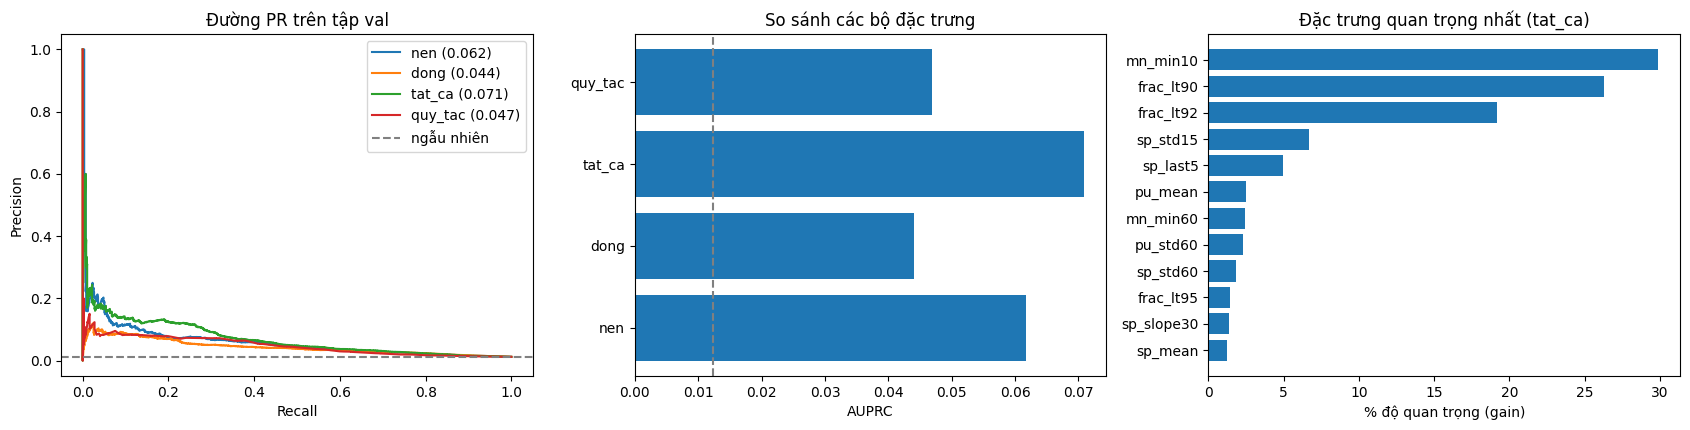

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for n, s in score["val"].items():
    p, r, _ = precision_recall_curve(yv, s); ax[0].plot(r, p, label=f"{n} ({tab.loc[n, 'AUPRC']:.3f})")
ax[0].axhline(prev, ls="--", c="gray", label="ngẫu nhiên"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Đường PR trên tập val"); ax[0].legend()
ax[1].barh(tab.index, tab["AUPRC"]); ax[1].axvline(prev, ls="--", c="gray"); ax[1].set_xlabel("AUPRC"); ax[1].set_title("So sánh các bộ đặc trưng")
imp = pd.Series(models["tat_ca"].feature_importance("gain"), index=models["tat_ca"].feature_name()).sort_values().tail(12)
ax[2].barh(imp.index, imp.values / imp.values.sum() * 100); ax[2].set_xlabel("% độ quan trọng (gain)"); ax[2].set_title("Đặc trưng quan trọng nhất (tat_ca)")
plt.tight_layout(); plt.show()

TEST | tỷ lệ dương (mốc ngẫu nhiên): 0.0128 | bệnh nhân: 119 | cửa sổ dương: 917


,AUPRC,CI95,AUROC,AUPRC_1Hz,AUPRC_1phut,nhay@0.5/h,CBG/h thực@0.5,nhay@1/h,CBG/h thực@1,nhay@2/h,CBG/h thực@2
tat_ca,0.083671,0.049-0.114,0.812054,0.089442,0.070181,0.367503,0.553117,0.487459,1.029498,0.666303,2.037774
quy_tac,0.050309,0.035-0.066,0.774653,0.054683,0.045048,0.273719,0.531387,0.440567,0.96821,0.600872,1.884979


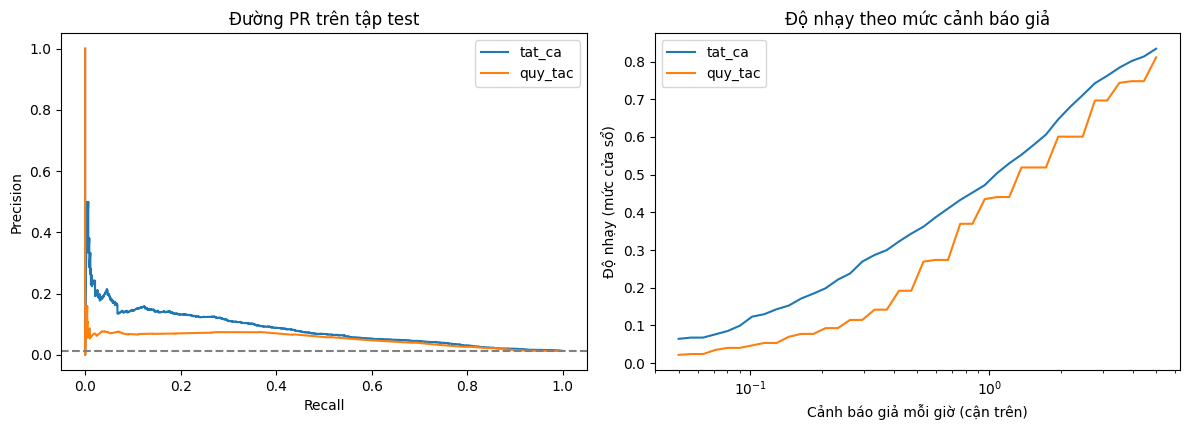

In [4]:
FINAL = "tat_ca"   # chỉ đổi sau khi đã xem kết quả val, rồi chạy cell này MỘT LẦN
yt, pid_t, h_t = F["test"]["y"].to_numpy(), F["test"]["pid"].to_numpy(), F["test"]["is_1hz"].to_numpy()
codes, uniq = pd.factorize(pid_t); idx_by = [np.where(codes == i)[0] for i in range(len(uniq))]

def boot_ci(s, n=200, seed=0):          # khoảng tin cậy 95%, lấy mẫu lại theo bệnh nhân
    rng, out = np.random.default_rng(seed), []
    for _ in range(n):
        ii = np.concatenate([idx_by[i] for i in rng.integers(0, len(uniq), len(uniq))])
        if yt[ii].sum(): out.append(average_precision_score(yt[ii], s[ii]))
    return np.percentile(out, [2.5, 97.5])

def hours(y): return (y == 0).sum() * STRIDE / 60       # số giờ theo dõi (gần đúng) của các cửa sổ âm

def thr_for_fa(s, y, fa):                               # ngưỡng cho phép <= fa cảnh báo giả/giờ
    neg = np.sort(s[y == 0])[::-1]; return neg[min(int(fa * hours(y)), len(neg) - 1)]

rows = {}
for n in (FINAL, "quy_tac"):
    s = score["test"][n]; lo, hi = boot_ci(s)
    r = {"AUPRC": average_precision_score(yt, s), "CI95": f"{lo:.3f}-{hi:.3f}", "AUROC": roc_auc_score(yt, s),
         "AUPRC_1Hz": average_precision_score(yt[h_t], s[h_t]), "AUPRC_1phut": average_precision_score(yt[~h_t], s[~h_t])}
    for fa in (0.5, 1, 2):                              # ngưỡng chọn trên val, áp lên test
        thr = thr_for_fa(score["val"][n], yv, fa); pred = s > thr
        r[f"nhay@{fa}/h"] = pred[yt == 1].mean(); r[f"CBG/h thực@{fa}"] = pred[yt == 0].sum() / hours(yt)
    rows[n] = r
print(f"TEST | tỷ lệ dương (mốc ngẫu nhiên): {yt.mean():.4f} | bệnh nhân: {len(uniq)} | cửa sổ dương: {int(yt.sum())}")
display(pd.DataFrame(rows).T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for n in (FINAL, "quy_tac"):
    s = score["test"][n]; p, r_, _ = precision_recall_curve(yt, s); ax[0].plot(r_, p, label=n)
    neg = np.sort(s[yt == 0])[::-1]; fa = np.geomspace(0.05, 5, 40)
    ax[1].plot(fa, [(s > neg[min(int(f * hours(yt)), len(neg) - 1)])[yt == 1].mean() for f in fa], label=n)
ax[0].axhline(yt.mean(), ls="--", c="gray"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Đường PR trên tập test"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_xlabel("Cảnh báo giả mỗi giờ (cận trên)"); ax[1].set_ylabel("Độ nhạy (mức cửa sổ)")
ax[1].set_title("Độ nhạy theo mức cảnh báo giả"); ax[1].legend(); plt.tight_layout(); plt.show()

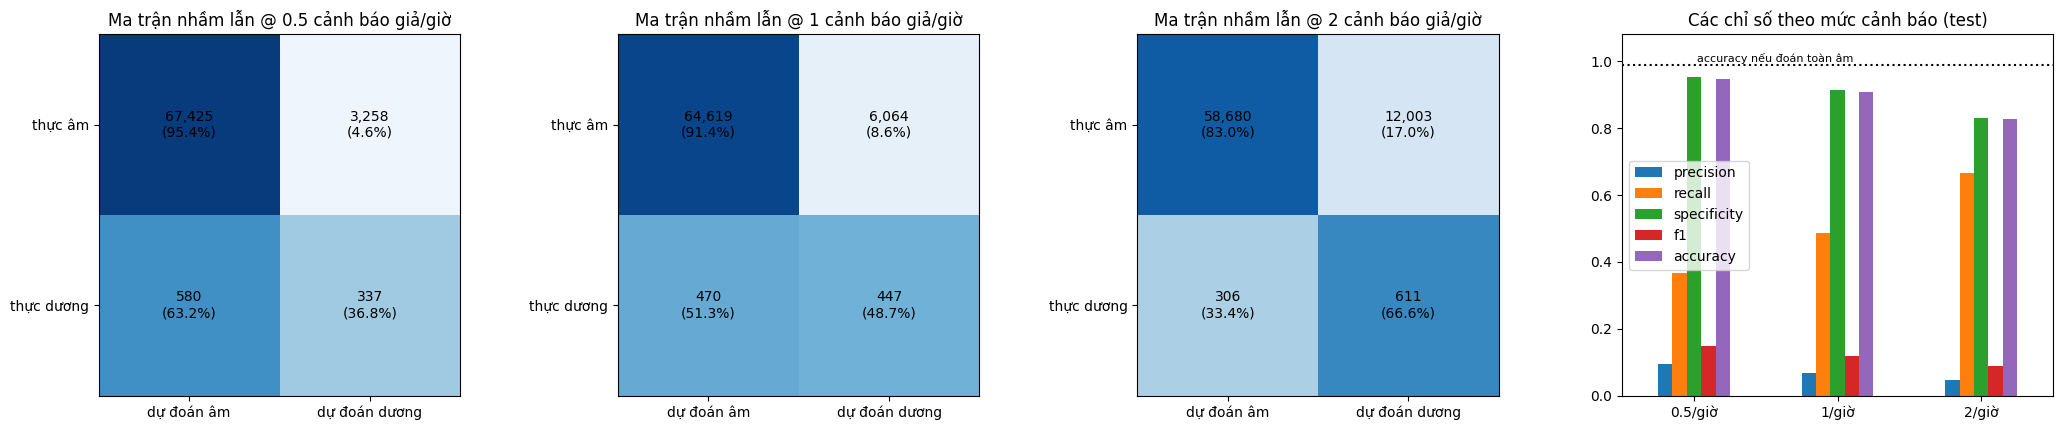

,precision,recall,specificity,f1,accuracy
0.5/giờ,0.094,0.368,0.954,0.149,0.946
1/giờ,0.069,0.487,0.914,0.120,0.909
2/giờ,0.048,0.666,0.830,0.090,0.828


Chênh AUPRC (tat_ca - quy_tac): khoảng tin cậy 95% = [0.013, 0.053] | model hơn quy tắc trong 100% lần lấy mẫu lại


In [5]:
from sklearn.metrics import confusion_matrix
s_v, s_t = score["val"][FINAL], score["test"][FINAL]
fig, ax = plt.subplots(1, 4, figsize=(21, 4.4)); res = {}
for a, fa in zip(ax[:3], (0.5, 1, 2)):
    thr = thr_for_fa(s_v, yv, fa)                       # ngưỡng chọn trên val
    tn, fp, fn, tp = confusion_matrix(yt, (s_t > thr).astype(int)).ravel()
    res[f"{fa}/giờ"] = dict(precision=tp / max(tp + fp, 1), recall=tp / (tp + fn), specificity=tn / (tn + fp),
                            f1=2 * tp / (2 * tp + fp + fn), accuracy=(tp + tn) / len(yt))
    cm = np.array([[tn, fp], [fn, tp]]); a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center")
    a.set_xticks([0, 1]); a.set_xticklabels(["dự đoán âm", "dự đoán dương"]); a.set_yticks([0, 1]); a.set_yticklabels(["thực âm", "thực dương"])
    a.set_title(f"Ma trận nhầm lẫn @ {fa} cảnh báo giả/giờ")
R = pd.DataFrame(res).T; R.plot.bar(ax=ax[3], rot=0)
ax[3].axhline(1 - yt.mean(), ls=":", c="k"); ax[3].text(0.02, 1 - yt.mean() + .01, "accuracy nếu đoán toàn âm", fontsize=8)
ax[3].set_ylim(0, 1.08); ax[3].set_title("Các chỉ số theo mức cảnh báo (test)"); plt.tight_layout(); plt.show()
display(R.round(3))

def boot_diff(s1, s2, n=200, seed=0):                   # so sánh cặp: cùng một mẫu bệnh nhân cho cả hai
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        ii = np.concatenate([idx_by[i] for i in rng.integers(0, len(uniq), len(uniq))])
        if yt[ii].sum(): d.append(average_precision_score(yt[ii], s1[ii]) - average_precision_score(yt[ii], s2[ii]))
    return np.percentile(d, [2.5, 97.5]), np.mean(np.array(d) > 0)
ci, frac = boot_diff(score["test"][FINAL], score["test"]["quy_tac"])
print(f"Chênh AUPRC ({FINAL} - quy_tac): khoảng tin cậy 95% = [{ci[0]:.3f}, {ci[1]:.3f}] | "
      f"model hơn quy tắc trong {frac:.0%} lần lấy mẫu lại")

### Đánh giá model

In [6]:
import numpy as np, eval_utils as E
ld = lambda k: np.load(f"{DATA_DIR}/{k}.npz")
MV = {c: ld("val")[c] for c in ("pid", "rec", "start")}
MT = {c: ld("test")[c] for c in ("pid", "rec", "start")}
isp = lambda n: n != "quy_tac"

,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE
model,,,,,,,,,
nen,0.062,0.036-0.099,5.010,0.759,0.012,868,121,0.012,0.001
dong,0.044,0.029-0.067,3.582,0.758,0.012,868,121,0.012,0.003
tat_ca,0.071,0.042-0.114,5.756,0.771,0.012,868,121,0.012,0.004
quy_tac,0.047,0.030-0.075,3.812,0.728,0.012,868,121,NaN,NaN


thr  precision  recall  specificity     f1  accuracy  \
model   FA/giờ                                                            
nen     0.04     0.142      0.159   0.051        0.997  0.077     0.985   
        0.50     0.045      0.075   0.272        0.958  0.118     0.950   
        1.00     0.031      0.057   0.407        0.917  0.101     0.910   
        2.00     0.017      0.039   0.546        0.833  0.073     0.830   
dong    0.04     0.108      0.090   0.026        0.997  0.041     0.985   
        0.50     0.042      0.063   0.225        0.958  0.098     0.949   
        1.00     0.028      0.048   0.340        0.917  0.085     0.910   
        2.00     0.016      0.037   0.517        0.833  0.069     0.829   
tat_ca  0.04     0.127      0.169   0.054        0.997  0.082     0.985   
        0.50     0.034      0.086   0.315        0.958  0.135     0.950   
        1.00     0.022      0.060   0.427        0.917  0.105     0.911   
        2.00     0.014      0.041   0.571        0.833  0.076     0.830   
quy_tac 0.04   -74.000      0.101   0.028        0.997  0.043     0.985   
        0.50   -88.000      0.073   0.243        0.962  0.113     0.953   
        1.00   -90.000      0.064   0.380        0.931  0.110     0.924   
        2.00   -92.000      0.044   0.494        0.865  0.080     0.860   

                event_recall  FA_per_h  FA_per_day  
model   FA/giờ                                      
nen     0.04           0.075     0.040       0.959  
        0.50           0.412     0.500      11.992  
        1.00           0.544     0.999      23.972  
        2.00           0.700     2.000      47.990  
dong    0.04           0.081     0.040       0.959  
        0.50           0.431     0.500      11.996  
        1.00           0.588     1.000      23.997  
        2.00           0.762     2.000      47.998  
tat_ca  0.04           0.162     0.040       0.955  
        0.50           0.494     0.500      11.996  
        1.00           0.656     1.000      23.997  
        2.00           0.788     2.000      47.998  
quy_tac 0.04           0.075     0.037       0.881  
        0.50           0.506     0.459      11.012  
        1.00           0.631     0.829      19.891  
        2.00           0.731     1.624      38.967

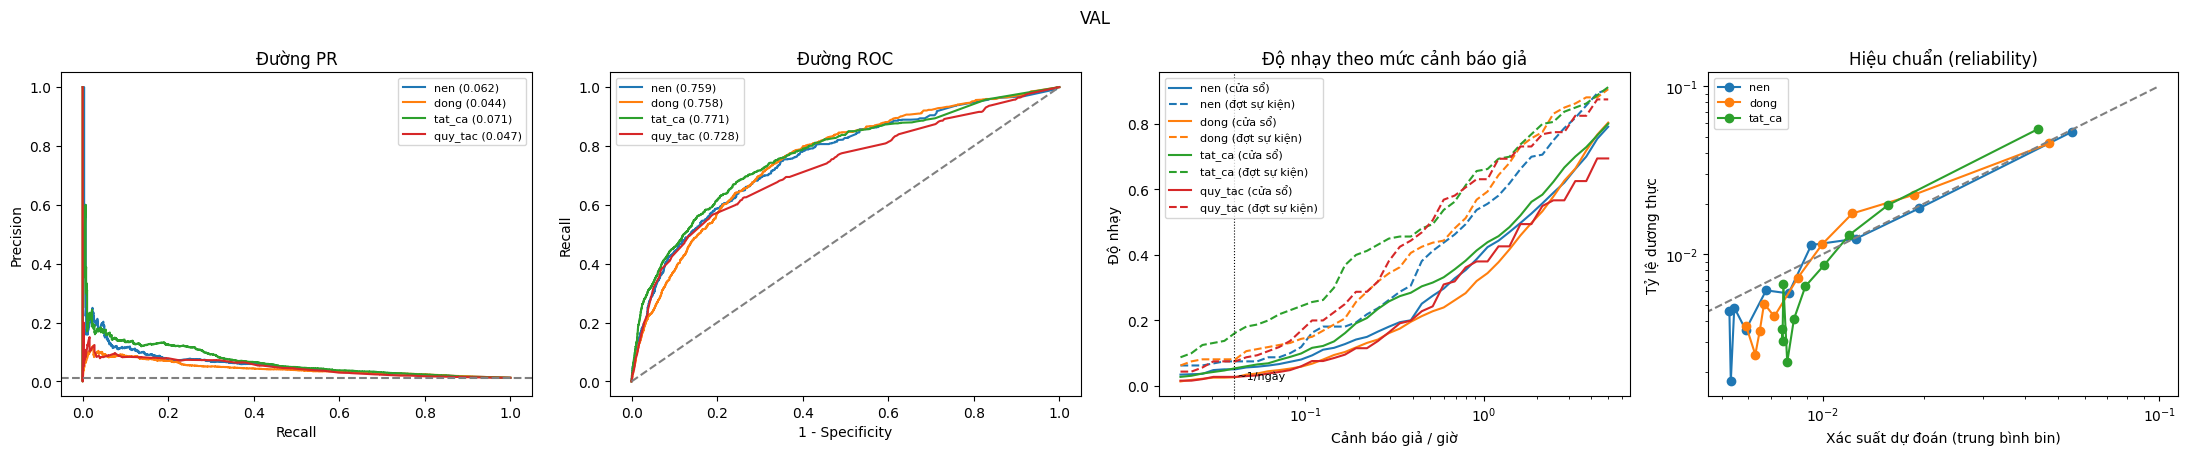

In [7]:
thr = {n: E.pick_thresholds(score["val"][n], yv) for n in score["val"]}
cv = [E.evaluate(n, score["val"][n], yv, thr[n], MV, is_prob=isp(n)) for n in score["val"]]
t1, t2 = E.report(cv); display(t1.round(3)); display(t2.round(3))
E.plot_curves(cv, "VAL")

,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE,Brier_isotonic,ECE_isotonic
model,,,,,,,,,,,
tat_ca,0.084,0.049-0.114,6.533,0.812,0.013,917,119,0.012,0.006,0.012,0.003
quy_tac,0.050,0.035-0.066,3.928,0.775,0.013,917,119,NaN,NaN,NaN,NaN


thr  precision  recall  specificity     f1  accuracy  \
model   FA/giờ                                                            
tat_ca  0.04     0.127      0.177   0.058        0.997  0.087     0.984   
        0.50     0.034      0.094   0.368        0.954  0.149     0.946   
        1.00     0.022      0.069   0.487        0.914  0.120     0.909   
        2.00     0.014      0.048   0.666        0.830  0.090     0.828   
quy_tac 0.04   -74.000      0.064   0.015        0.997  0.025     0.985   
        0.50   -88.000      0.074   0.274        0.956  0.117     0.947   
        1.00   -90.000      0.066   0.441        0.919  0.115     0.913   
        2.00   -92.000      0.047   0.601        0.843  0.088     0.840   

                event_recall  FA_per_h  FA_per_day  
model   FA/giờ                                      
tat_ca  0.04           0.167     0.042       1.006  
        0.50           0.649     0.553      13.275  
        1.00           0.750     1.029      24.708  
        2.00           0.851     2.038      48.907  
quy_tac 0.04           0.048     0.035       0.835  
        0.50           0.589     0.531      12.753  
        1.00           0.720     0.968      23.237  
        2.00           0.815     1.885      45.240

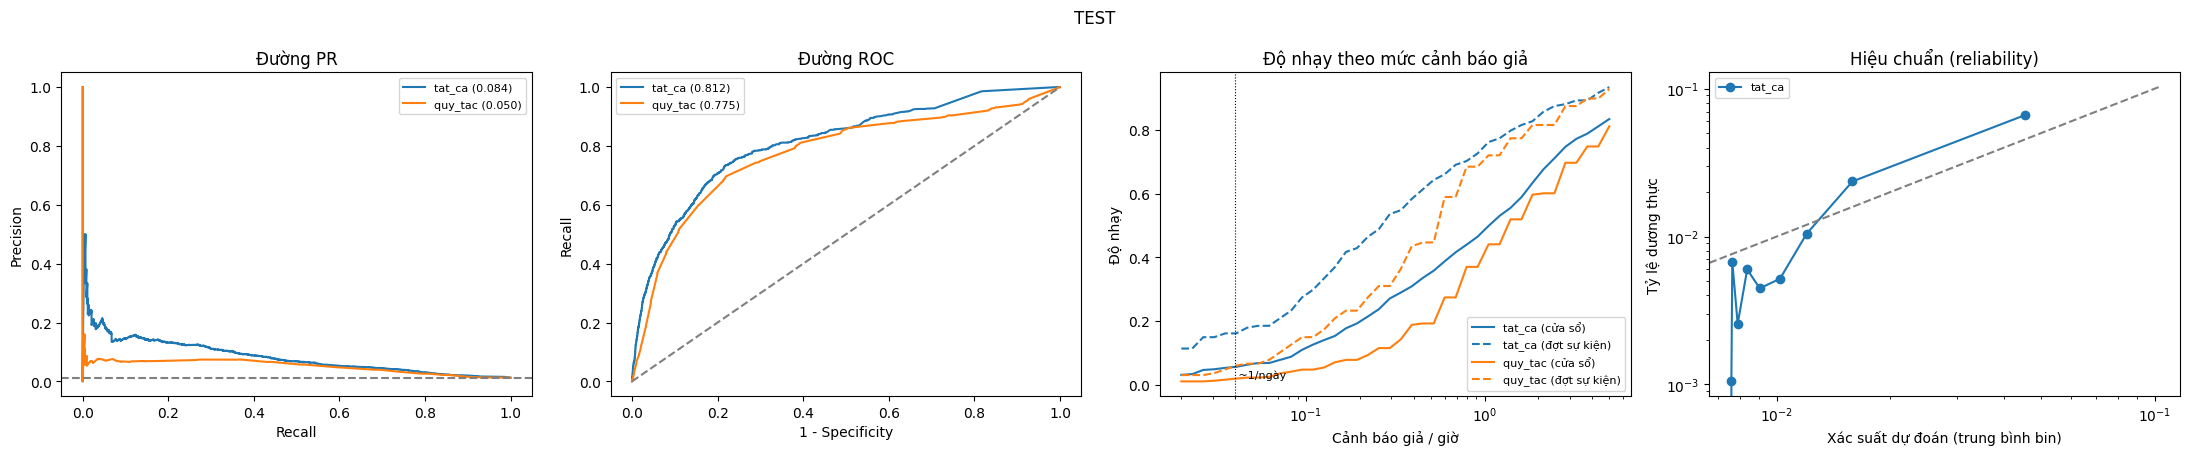

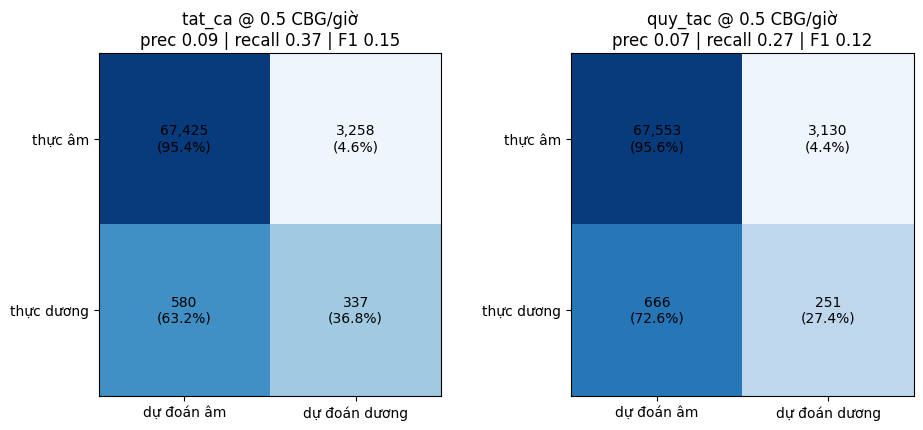

In [8]:
FINAL = "tat_ca"
ct = [E.evaluate(n, score["test"][n], yt, thr[n], MT, s_val=score["val"][n], y_val=yv, is_prob=isp(n))
      for n in (FINAL, "quy_tac")]
t1, t2 = E.report(ct); display(t1.round(3)); display(t2.round(3))
E.plot_curves(ct, "TEST"); E.plot_confusions(ct, fa=0.5)

In [9]:
import importlib, sim_alert as SA; importlib.reload(SA)
CLEAN_DIR = os.path.join(os.path.dirname(DATA_DIR), "clean_1min")   # cùng thư mục cha với dataset_thr88
assert os.path.isdir(CLEAN_DIR), f"Không thấy {CLEAN_DIR}"
FINAL = "tat_ca"
tl_val  = SA.build_timelines(score["val"][FINAL],  MV, CLEAN_DIR)
tl_test = SA.build_timelines(score["test"][FINAL], MT, CLEAN_DIR)
print(len(tl_val), "record val |", len(tl_test), "record test")

193 record val | 182 record test


,fa_budget,k,n,cooldown,alerts_per_day,FA_per_day,FA_day_pt_p90,precision,caught_useful,missed,lead_med
0,0.04,1,1,30,0.56,0.46,1.43,0.18,0.11,0.85,10.0
1,0.04,1,1,60,0.47,0.39,1.15,0.17,0.09,0.87,8.5
2,0.04,2,3,30,0.23,0.20,0.72,0.14,0.04,0.96,16.0
3,0.04,2,3,60,0.20,0.17,0.70,0.14,0.03,0.96,17.0
4,0.04,3,4,30,0.14,0.12,0.51,0.15,0.04,0.96,16.0
5,0.04,3,4,60,0.12,0.10,0.45,0.17,0.04,0.96,16.0
6,0.04,4,6,30,0.10,0.08,0.10,0.20,0.03,0.96,8.5
7,0.04,4,6,60,0.09,0.07,0.10,0.22,0.03,0.96,8.5
8,0.20,1,1,30,2.05,1.81,5.47,0.12,0.30,0.60,12.0
9,0.20,1,1,60,1.62,1.41,4.71,0.13,0.28,0.65,12.0


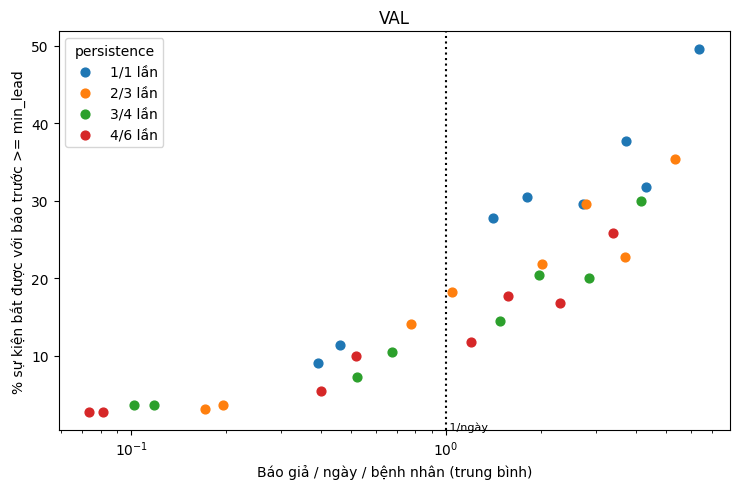

In [10]:
thr_map = E.pick_thresholds(score["val"][FINAL], yv, fa_levels=(0.04, 0.2, 0.5, 1))
sw = SA.sweep(tl_val, thr_map)            # 4 ngưỡng x 4 persistence x 2 cooldown = 32 lần chạy
display(sw[SA.SHOW].round(2)); SA.plot_tradeoff(sw, title="VAL")

fa_budget          0.200000
k                  1.000000
n                  1.000000
cooldown          30.000000
alerts_per_day     2.054430
FA_per_day         1.805284
FA_day_pt_p90      5.471896
precision          0.121272
caught_useful      0.304545
missed             0.604545
lead_med          12.000000
Name: 8, dtype: float64

,TEST
alerts_per_day,2.212
FA_per_day,1.919
precision,0.133
caught_any,0.413
caught_useful,0.307
missed,0.587
lead_med,11.000
lead_p25,4.250
FA_day_pt_med,1.051
FA_day_pt_p90,5.936


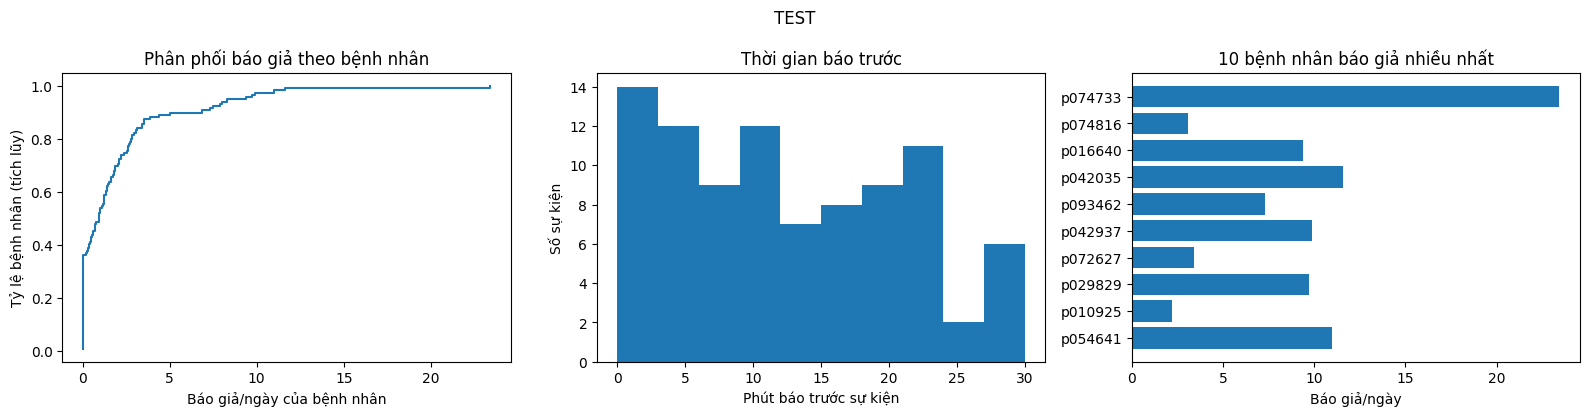

Tầng Critical (luật SpO2<88% >=3 phút): {'alerts_per_day': np.float64(0.94), 'FA_day_pt_med': np.float64(0.19), 'FA_day_pt_p90': np.float64(2.92), 'FA_day_pt_max': np.float64(8.11), 'n_events': 262, 'patients': 111}


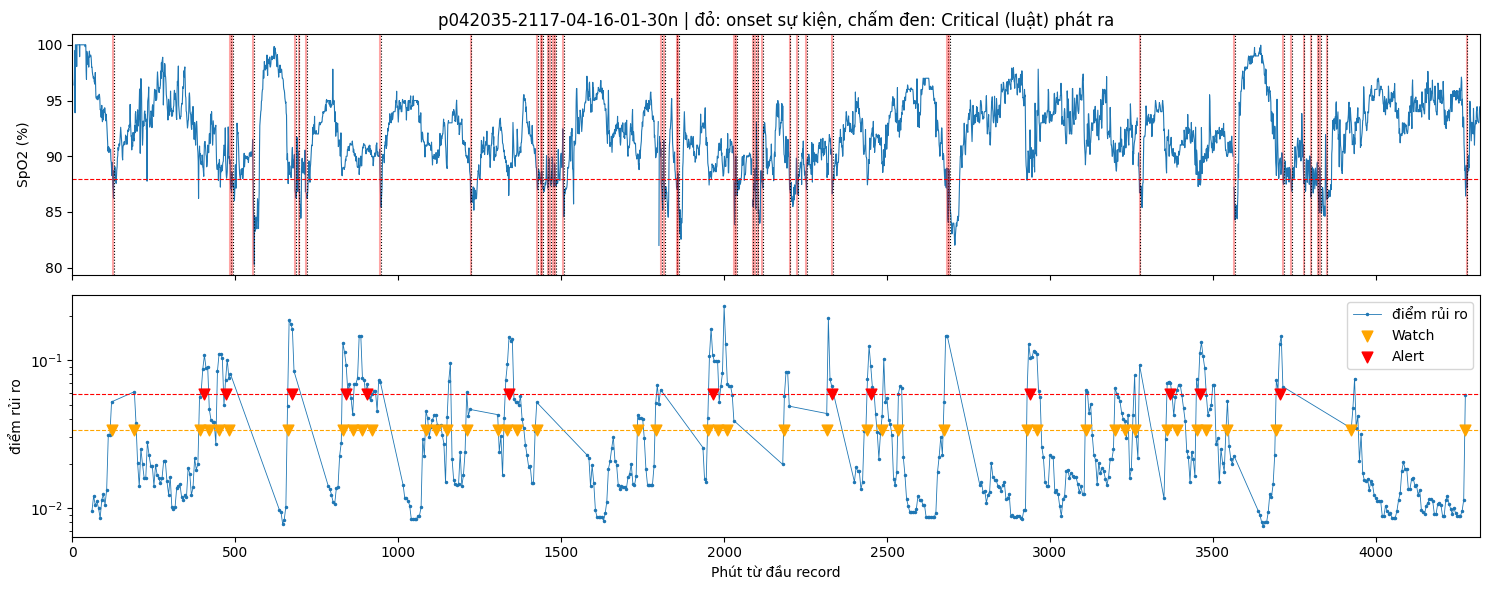

In [11]:
MAX_FA_DAY = 2        # ngân sách báo giả/ngày/bệnh nhân bạn chấp nhận được
cand = sw[sw["FA_per_day"] <= MAX_FA_DAY].sort_values("caught_useful", ascending=False)
assert len(cand), "Không cấu hình nào đạt ngân sách báo giả, hãy tăng MAX_FA_DAY"
best = cand.iloc[0]; display(best[SA.SHOW])

summ, pt, leads = SA.run_stream(tl_test, best["thr"], int(best["k"]), int(best["n"]), int(best["cooldown"]))
display(pd.Series(summ).round(3).to_frame("TEST"))
SA.plot_config(pt, leads, "TEST")
print("Tầng Critical (luật SpO2<88% >=3 phút):", {k: round(v, 2) for k, v in SA.critical_stats(tl_test).items()})
SA.plot_example(tl_test, thr_map[0.5], best["thr"])      # vẽ 1 record: SpO2, sự kiện, điểm rủi ro, Watch/Alert

In [12]:
os.makedirs("runs", exist_ok=True)
for k in ("val", "test"):
    np.save(f"runs/lgbm_{k}.npy", score[k]["tat_ca"])
    np.save(f"runs/rule_{k}.npy", score[k]["quy_tac"])